### Notebook 05 — 5-Year Incline / Decline Prediction (2025–2029)

**Question:** which fishing regions keep declining vs keep increasing over the next 5 years, and by how much?

**Method (Both: classes + values, at cluster-region level):**
1. Reload `cell_effort_trends.parquet` + `annual_cell_effort_2015_2024.parquet` + `hdbscan_spatial_clusters.parquet` (read-only, no reprocessing).
2. Refit per-cell OLS on `mean_monthly_fishing_hours` vs year, compute residual std `s`, then extrapolate `yhat = intercept + slope*year` for 2025–2029 with 95% prediction intervals.
3. Convert slope uncertainty into `P(decline) = Phi(-slope/SE_slope)` / `P(increase) = Phi(slope/SE_slope)` + rule-based future class (slope sign + `p<0.05`).
4. Pool cells into regions (decline pocket, increase belt, south tip, rest) and repeat the pooled forecast.
5. Backtest: train ≤2023 \rightarrow predict 2024 vs naive (last value), report MAE + interval coverage.

**Limits up front:** only 557/8697 cells have \u22655 years; 7 decliners so uncertainty is wide; no zero-fill (missing year = no data, not zero); AIS coverage grew 2015–2024 so part of any increase is detection; 1–3 yr direction is defensible, 4–5 yr values are scenarios, not promises.

### 1. Setup + load

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from scipy.stats import linregress, norm, t

# Robust root: works whether kernel cwd is notebooks/ or repo root
CANDS = [Path(".."), Path(".")]
BASE_DIR = next((p for p in CANDS if (p / "outputs" / "analysis").exists()), Path(".."))
ANALYSIS_DIR = BASE_DIR / "outputs" / "analysis"
FIG_DIR = BASE_DIR / "outputs" / "figures" / "nb05"
GEO_PATH = BASE_DIR / "outputs" / "geo" / "ne_110m_admin_0_countries.geojson"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("BASE_DIR:", BASE_DIR.resolve())
print("GEO exists:", GEO_PATH.exists())

TREND = pd.read_parquet(ANALYSIS_DIR / "cell_effort_trends.parquet")
ANNUAL = pd.read_parquet(ANALYSIS_DIR / "annual_cell_effort_2015_2024.parquet")
SPAT = pd.read_parquet(ANALYSIS_DIR / "hdbscan_spatial_clusters.parquet")
print("trends:", TREND.shape, "annual:", ANNUAL.shape, "spat:", SPAT.shape)
print(TREND["trend_class"].value_counts().to_string())

FORECAST_YEARS = [2025, 2026, 2027, 2028, 2029]
ALPHA = 0.05


BASE_DIR: D:\ResearchPapers\AIS_Data_Analysis
GEO exists: True
trends: (8697, 16) annual: (19730, 12) spat: (557, 19)
trend_class
Insufficient data           8140
Stable / not significant     511
Increasing                    39
Declining                      7


### 2. Per-cell refit + 5-year forecast (values + intervals + probabilities)

In [2]:
ELIG_CLASSES = ["Declining", "Increasing", "Stable / not significant"]
elig = TREND[TREND["trend_class"].isin(ELIG_CLASSES)].copy()
print("eligible cells:", len(elig))

# annual series uses mean_monthly_fishing_hours (same metric nb03 trend was fit on)
A = ANNUAL[["cell_ll_lat", "cell_ll_lon", "year", "mean_monthly_fishing_hours"]].copy()
A = A.dropna(subset=["mean_monthly_fishing_hours"])

def fit_forecast(xy, years_out):
    """OLS refit + forecast with 95% prediction interval + slope-sign probabilities."""
    x = xy["year"].to_numpy(float); y = xy["mean_monthly_fishing_hours"].to_numpy(float)
    n = len(x)
    if n < 5:
        return None
    r = linregress(x, y)
    slope, intercept, p = float(r.slope), float(r.intercept), float(r.pvalue)
    yhat_hist = intercept + slope * x
    sse = float(np.sum((y - yhat_hist) ** 2))
    s = float(np.sqrt(sse / (n - 2))) if n > 2 else np.nan
    xmean = float(x.mean()); ssxx = float(np.sum((x - xmean) ** 2))
    se_slope = float(s / np.sqrt(ssxx)) if ssxx > 0 and s == s else np.nan
    # P(true slope < 0) under Normal(slope_hat, se_slope)
    if se_slope and se_slope > 0:
        p_decline = float(norm.cdf(-slope / se_slope))
    else:
        p_decline = float(1.0 if slope < 0 else 0.0)
    p_increase = float(1.0 - p_decline)
    tcrit = float(t.ppf(0.975, n - 2)) if n > 2 else 1.96
    last = float(y[x.argmax()])
    rows = []
    for yr in years_out:
        yh = float(intercept + slope * yr)
        se_pred = float(s * np.sqrt(1 + 1 / n + (yr - xmean) ** 2 / ssxx)) if ssxx > 0 else np.nan
        lo, hi = yh - tcrit * se_pred, yh + tcrit * se_pred
        rows.append({"year": yr, "yhat_raw": yh, "yhat": max(yh, 0.0),
                       "pi_lo": max(lo, 0.0), "pi_hi": max(hi, 0.0),
                       "slope": slope, "intercept": intercept, "p_value": p,
                       "resid_s": s, "se_slope": se_slope, "n_years": n,
                       "p_decline": p_decline, "p_increase": p_increase,
                       "last_effort": last})
    return rows

long_rows, sum_rows = [], []
for (la, lo), g in A.groupby(["cell_ll_lat", "cell_ll_lon"]):
    out = fit_forecast(g.sort_values("year"), FORECAST_YEARS)
    if out is None:
        continue
    tr = elig[(elig["cell_ll_lat"] == la) & (elig["cell_ll_lon"] == lo)]
    past_class = tr["trend_class"].iloc[0] if len(tr) else "Unknown"
    for r in out:
        r.update({"cell_ll_lat": la, "cell_ll_lon": lo, "past_class": past_class})
        long_rows.append(r)
    f29 = [r for r in out if r["year"] == 2029][0]
    f25 = [r for r in out if r["year"] == 2025][0]
    slope, p = f29["slope"], f29["p_value"]
    if slope < 0 and p < ALPHA:
        fut = "Predicted Declining"
    elif slope > 0 and p < ALPHA:
        fut = "Predicted Increasing"
    else:
        fut = "Predicted Stable"
    last = f29["last_effort"]
    d29 = f29["yhat"] - last
    pct29 = (d29 / last * 100) if last > 0 else np.nan
    sum_rows.append({"cell_ll_lat": la, "cell_ll_lon": lo, "past_class": past_class,
                     "n_years": f29["n_years"], "slope": slope, "p_value": p,
                     "p_decline": f29["p_decline"], "p_increase": f29["p_increase"],
                     "future_class": fut, "last_effort": last,
                     "pred_2025": f25["yhat"], "pred_2029": f29["yhat"],
                     "pi_lo_2029": f29["pi_lo"], "pi_hi_2029": f29["pi_hi"],
                     "delta_2029": d29, "pct_2029": pct29,
                     "hits_zero_by_2029": bool(f29["yhat"] <= 0.01)})

CELL_LONG = pd.DataFrame(long_rows)
CELL_SUM = pd.DataFrame(sum_rows)
print("forecast cells:", CELL_SUM.shape, "long rows:", CELL_LONG.shape)
print(CELL_SUM["future_class"].value_counts().to_string())
CELL_SUM.sort_values("slope").head(8).round(3)

eligible cells: 557
forecast cells: (557, 17) long rows: (2785, 17)
future_class
Predicted Stable        511
Predicted Increasing     39
Predicted Declining       7


,cell_ll_lat,cell_ll_lon,past_class,n_years,slope,p_value,p_decline,p_increase,future_class,last_effort,pred_2025,pred_2029,pi_lo_2029,pi_hi_2029,delta_2029,pct_2029,hits_zero_by_2029
514,18.5,72.0,Declining,5,-10.875,0.029,1.000,0.000,Predicted Declining,1.276,0.000,0.0,0.0,20.849,-1.276,-100.0,True
354,17.0,72.8,Declining,8,-8.722,0.045,0.994,0.006,Predicted Declining,8.920,0.000,0.0,0.0,49.034,-8.920,-100.0,True
515,18.5,72.3,Stable / not significant,5,-8.485,0.176,0.961,0.039,Predicted Stable,3.437,0.000,0.0,0.0,104.129,-3.437,-100.0,True
353,17.0,72.7,Stable / not significant,8,-8.349,0.122,0.964,0.036,Predicted Stable,6.685,0.000,0.0,0.0,83.922,-6.685,-100.0,True
392,17.3,71.7,Stable / not significant,5,-8.004,0.420,0.825,0.175,Predicted Stable,8.590,0.000,0.0,0.0,181.002,-8.590,-100.0,True
184,15.7,72.6,Stable / not significant,5,-7.284,0.159,0.969,0.031,Predicted Stable,12.636,13.411,0.0,0.0,81.469,-12.636,-100.0,True
516,18.5,72.4,Declining,5,-6.567,0.009,1.000,0.000,Predicted Declining,4.046,0.000,0.0,0.0,0.000,-4.046,-100.0,True
421,17.5,71.4,Stable / not significant,5,-6.560,0.123,0.984,0.016,Predicted Stable,9.463,0.000,0.0,0.0,44.621,-9.463,-100.0,True


### 3. Region pooling (cluster-region level)

In [3]:
# Attach HDBSCAN spatial cluster; define analytic watch-regions for the forecast
CS = CELL_SUM.merge(SPAT[["cell_ll_lat", "cell_ll_lon", "spatial_cluster"]],
                    on=["cell_ll_lat", "cell_ll_lon"], how="left")

def assign_region(r):
    la, lo = r["cell_ll_lat"], r["cell_ll_lon"]
    if 17.0 <= la <= 18.7 and 71.9 <= lo <= 72.9:
        return "decline_pocket (Mumbai offshore)"
    if 13.5 <= la <= 15.5 and 73.0 <= lo <= 74.0:
        return "increase_belt (Karnataka/Goa)"
    if r["spatial_cluster"] == 2:
        return "south_tip (Kanyakumari)"
    return "rest_of_range"

CS["region"] = CS.apply(assign_region, axis=1)
print(CS.groupby(["region", "future_class"]).size().to_string())

# Pooled region series: sum of mean_monthly_fishing_hours across member cells per year
member = CS[["cell_ll_lat", "cell_ll_lon", "region"]]
RA = A.merge(member, on=["cell_ll_lat", "cell_ll_lon"], how="inner")
REG_ANN = RA.groupby(["region", "year"])["mean_monthly_fishing_hours"].sum().reset_index()
REG_ANN = REG_ANN.rename(columns={"mean_monthly_fishing_hours": "region_effort"})
print(REG_ANN.head(8).to_string())

reg_long, reg_sum = [], []
for reg, g in REG_ANN.groupby("region"):
    gg = g.sort_values("year").rename(columns={"region_effort": "mean_monthly_fishing_hours"})
    out = fit_forecast(gg, FORECAST_YEARS)
    if out is None:
        continue
    for r in out:
        r.update({"region": reg})
        reg_long.append(r)
    last = out[0]["last_effort"]
    f29 = [r for r in out if r["year"] == 2029][0]
    slope, p = f29["slope"], f29["p_value"]
    fut = ("Predicted Declining" if slope < 0 and p < ALPHA
           else "Predicted Increasing" if slope > 0 and p < ALPHA else "Predicted Stable")
    reg_sum.append({"region": reg, "n_years": f29["n_years"], "slope": slope, "p_value": p,
                    "p_decline": f29["p_decline"], "p_increase": f29["p_increase"],
                    "future_class": fut, "last_effort": last,
                    "pred_2029": f29["yhat"], "pi_lo_2029": f29["pi_lo"],
                    "pi_hi_2029": f29["pi_hi"],
                    "delta_2029": f29["yhat"] - last,
                    "pct_2029": ((f29["yhat"] - last) / last * 100) if last > 0 else np.nan})

REG_LONG = pd.DataFrame(reg_long)
REG_SUM = pd.DataFrame(reg_sum).sort_values("slope")
print(REG_SUM.round(3).to_string())


region                            future_class        
decline_pocket (Mumbai offshore)  Predicted Declining       7
                                  Predicted Increasing      1
                                  Predicted Stable        108
increase_belt (Karnataka/Goa)     Predicted Increasing     23
                                  Predicted Stable         79
rest_of_range                     Predicted Increasing     11
                                  Predicted Stable        306
south_tip (Kanyakumari)           Predicted Increasing      4
                                  Predicted Stable         18
                             region  year  region_effort
0  decline_pocket (Mumbai offshore)  2015       4.521400
1  decline_pocket (Mumbai offshore)  2016      37.619833
2  decline_pocket (Mumbai offshore)  2017    1607.881230
3  decline_pocket (Mumbai offshore)  2018    3006.727030
4  decline_pocket (Mumbai offshore)  2019    2516.768484
5  decline_pocket (Mumbai offshore)  2020    

### 4. Backtest: train ≤2023, predict 2024 (model vs naive)

In [4]:
bt_rows = []
for (la, lo), g in A.groupby(["cell_ll_lat", "cell_ll_lon"]):
    g = g.sort_values("year")
    if not ((g["year"] == 2024).any() and (g["year"] <= 2023).sum() >= 5):
        continue
    tr = g[g["year"] <= 2023]
    actual = float(g[g["year"] == 2024]["mean_monthly_fishing_hours"].iloc[0])
    out = fit_forecast(tr, [2024])
    if out is None:
        continue
    f = out[0]
    naive = float(tr.sort_values("year")["mean_monthly_fishing_hours"].iloc[-1])
    bt_rows.append({"cell_ll_lat": la, "cell_ll_lon": lo,
                     "pred_2024": f["yhat"], "pi_lo": f["pi_lo"], "pi_hi": f["pi_hi"],
                     "actual_2024": actual, "naive_2024": naive})
BT = pd.DataFrame(bt_rows)
mae_m = (BT["pred_2024"] - BT["actual_2024"]).abs().mean()
mae_n = (BT["naive_2024"] - BT["actual_2024"]).abs().mean()
cov = ((BT["actual_2024"] >= BT["pi_lo"]) & (BT["actual_2024"] <= BT["pi_hi"])).mean()
print(f"backtest cells: {len(BT)} | MAE model={mae_m:.2f} | MAE naive(last value)={mae_n:.2f} | 95% PI coverage={cov:.2%}")
BT.head(5).round(3)

backtest cells: 265 | MAE model=28.47 | MAE naive(last value)=21.59 | 95% PI coverage=94.72%


,cell_ll_lat,cell_ll_lon,pred_2024,pi_lo,pi_hi,actual_2024,naive_2024
0,8.0,77.1,35.293,1.237,69.349,57.458,28.442
1,8.0,77.2,29.349,6.770,51.928,23.004,26.934
2,8.4,76.7,58.322,19.815,96.829,17.122,44.146
3,12.3,74.9,25.919,0.000,95.950,13.980,26.095
4,12.8,74.6,956.199,381.255,1531.142,318.216,691.572


### 5. Exports

In [5]:
CELL_LONG.to_parquet(ANALYSIS_DIR / "cell_5yr_forecast_2025_2029.parquet", index=False)
CS.to_parquet(ANALYSIS_DIR / "cell_5yr_forecast_summary.parquet", index=False)
REG_LONG.to_parquet(ANALYSIS_DIR / "region_5yr_forecast_2025_2029.parquet", index=False)
REG_SUM.to_parquet(ANALYSIS_DIR / "region_decline_risk.parquet", index=False)
BT.to_parquet(ANALYSIS_DIR / "backtest_2024.parquet", index=False)
print("wrote:", sorted([p.name for p in ANALYSIS_DIR.glob('*5yr*')] + ['region_decline_risk.parquet', 'backtest_2024.parquet']))
print("decliners forecast:")
print(CS[CS["future_class"] == "Predicted Declining"].sort_values("slope").round(3).to_string())

wrote: ['backtest_2024.parquet', 'cell_5yr_forecast_2025_2029.parquet', 'cell_5yr_forecast_summary.parquet', 'region_5yr_forecast_2025_2029.parquet', 'region_decline_risk.parquet']
decliners forecast:
     cell_ll_lat  cell_ll_lon past_class  n_years   slope  p_value  p_decline  p_increase         future_class  last_effort  pred_2025  pred_2029  pi_lo_2029  pi_hi_2029  delta_2029  pct_2029  hits_zero_by_2029  spatial_cluster                            region
514         18.5         72.0  Declining        5 -10.875    0.029      1.000       0.000  Predicted Declining        1.276      0.000        0.0         0.0      20.849      -1.276    -100.0               True                6  decline_pocket (Mumbai offshore)
354         17.0         72.8  Declining        8  -8.722    0.045      0.994       0.006  Predicted Declining        8.920      0.000        0.0         0.0      49.034      -8.920    -100.0               True                6  decline_pocket (Mumbai offshore)
516         1

### 6. Map: predicted change by 2029 (India window)

geo fallback: Polygon.__init__() takes 2 positional arguments but 3 were given


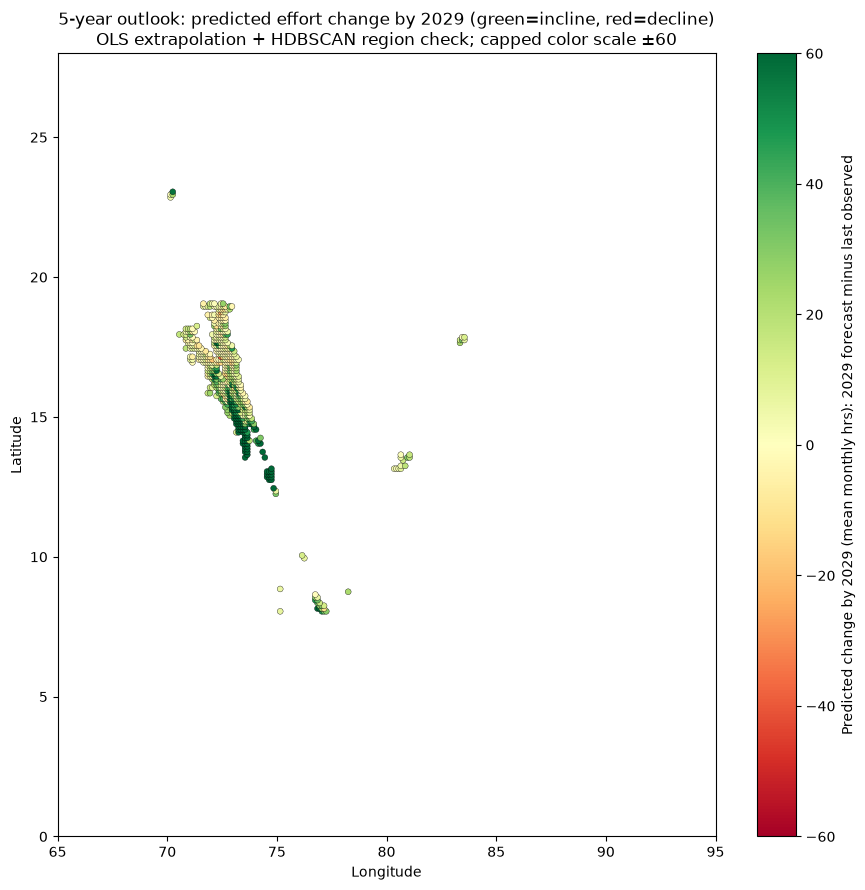

saved nb05_forecast_map_2029_change.png


In [6]:
world = json.load(open(GEO_PATH, encoding="utf-8"))
try:
    from matplotlib.collections import PatchCollection
    from matplotlib.patches import Polygon as MplPoly
    polys = []
    for feat in world["features"]:
        geom = feat["geometry"]
        if geom is None:
            continue
        t_, cs = geom["type"], geom["coordinates"]
        if t_ == "Polygon":
            polys.extend(cs)
        elif t_ == "MultiPolygon":
            for p in cs:
                polys.extend(p)
    patches = [MplPoly(np.array(r), True) for r in polys if len(r) > 2]
    HAS_GEO = True
except Exception as e:
    print("geo fallback:", e); HAS_GEO = False

fig, ax = plt.subplots(figsize=(9, 9))
if HAS_GEO:
    ax.add_collection(PatchCollection(patches, facecolor="#e8e8e8", edgecolor="#999999", linewidths=0.4, zorder=1))
sc = ax.scatter(CS["cell_ll_lon"] + 0.05, CS["cell_ll_lat"] + 0.05, c=CS["delta_2029"],
                cmap="RdYlGn", vmin=-60, vmax=60, s=18, edgecolors="k", linewidths=0.25, zorder=3)
plt.colorbar(sc, ax=ax, label="Predicted change by 2029 (mean monthly hrs): 2029 forecast minus last observed")
ax.set_xlim(65, 95); ax.set_ylim(0, 28)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("5-year outlook: predicted effort change by 2029 (green=incline, red=decline)\nOLS extrapolation + HDBSCAN region check; capped color scale \u00b160")
fig.tight_layout(); fig.savefig(FIG_DIR / "nb05_forecast_map_2029_change.png", dpi=200); plt.show()
print("saved nb05_forecast_map_2029_change.png")

### 7. Trajectories: decline pocket (history + 2025–2029 forecast + 95% band)

predicted decliners: 7


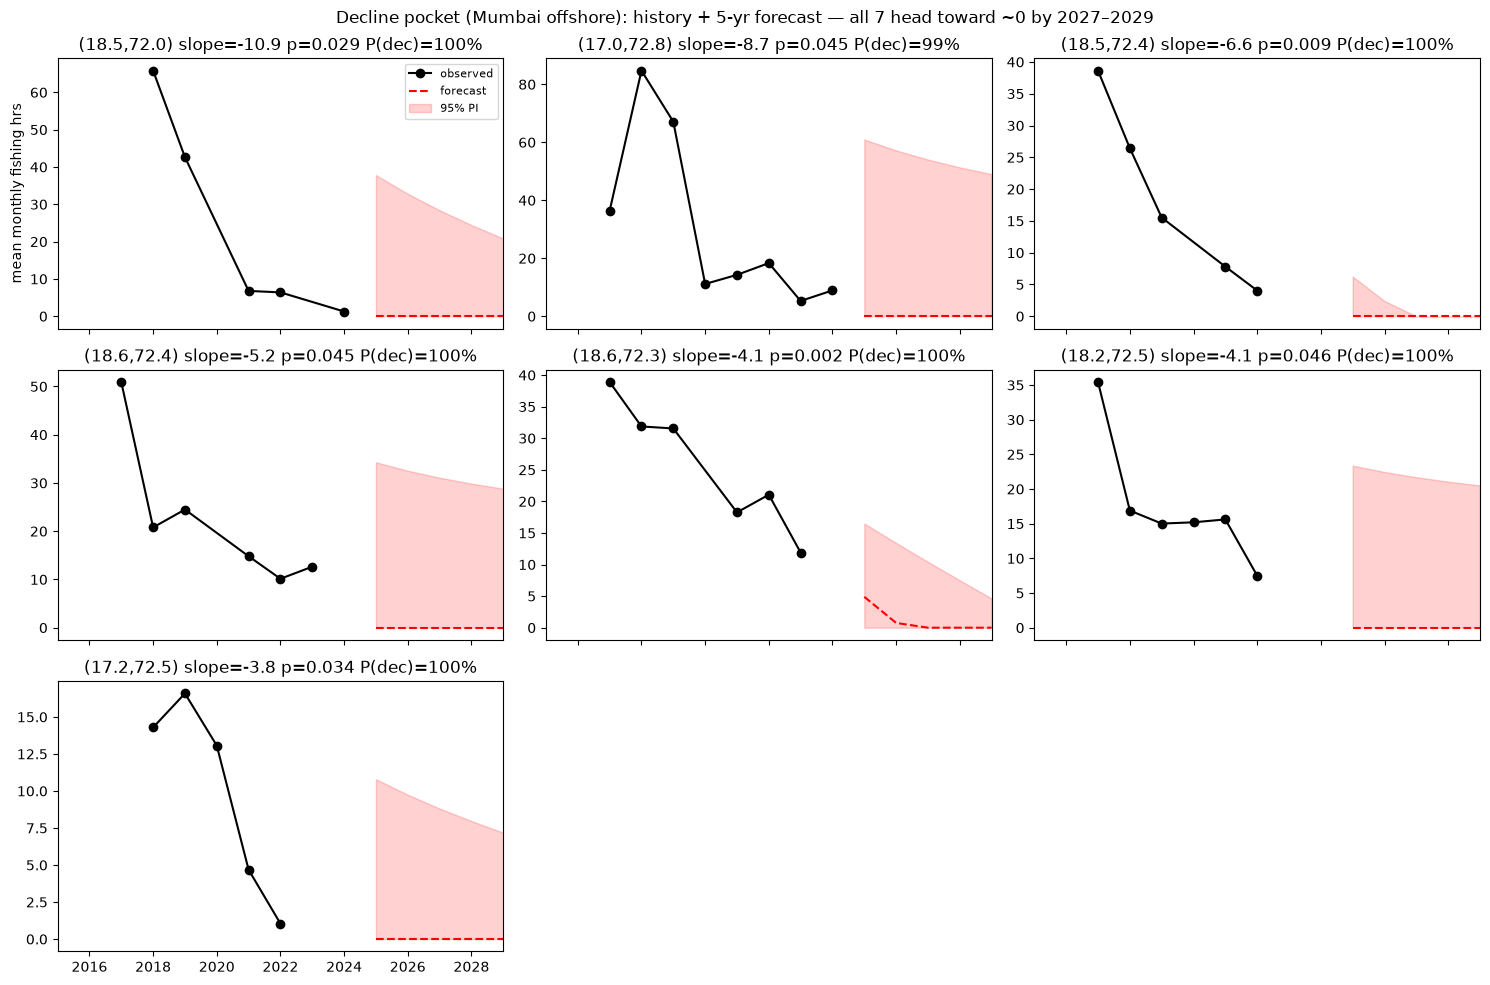

In [7]:
dec = CS[CS["future_class"] == "Predicted Declining"].sort_values("slope")
print("predicted decliners:", len(dec))
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharex=True, sharey=False)
axes = axes.ravel()
for i, (_, r) in enumerate(dec.iterrows()):
    ax = axes[i]
    la, lo = r["cell_ll_lat"], r["cell_ll_lon"]
    hist = A[(A["cell_ll_lat"] == la) & (A["cell_ll_lon"] == lo)].sort_values("year")
    fc = CELL_LONG[(CELL_LONG["cell_ll_lat"] == la) & (CELL_LONG["cell_ll_lon"] == lo)].sort_values("year")
    ax.plot(hist["year"], hist["mean_monthly_fishing_hours"], "ko-", label="observed")
    ax.plot(fc["year"], fc["yhat"], "r--", label="forecast")
    ax.fill_between(fc["year"], fc["pi_lo"], fc["pi_hi"], color="r", alpha=0.18, label="95% PI")
    ax.set_title(f"({la},{lo}) slope={r['slope']:.1f} p={r['p_value']:.3f} P(dec)={r['p_decline']:.0%}")
    ax.set_xlim(2015, 2029)
for j in range(len(dec), len(axes)):
    axes[j].axis("off")
axes[0].legend(fontsize=8); axes[0].set_ylabel("mean monthly fishing hrs")
fig.suptitle("Decline pocket (Mumbai offshore): history + 5-yr forecast — all 7 head toward ~0 by 2027–2029")
fig.tight_layout(); fig.savefig(FIG_DIR / "nb05_trajectories_decline_pocket.png", dpi=200); plt.show()

### 8. Trajectories: top increasers + pooled region outlook

    cell_ll_lat  cell_ll_lon  slope  p_value  last_effort  pred_2029  p_increase
49         13.6         73.6  63.50     0.04       329.35     595.88         1.0
53         13.7         73.6  49.27     0.04       265.84     465.61         1.0
57         13.9         73.5  48.73     0.03       177.27     442.11         1.0
52         13.7         73.5  43.56     0.04       206.58     419.23         1.0
56         13.8         73.6  42.84     0.04       235.51     409.83         1.0
55         13.8         73.5  40.03     0.01       207.94     383.91         1.0
58         13.9         73.6  39.69     0.02       210.92     381.37         1.0
88         14.6         73.4  33.30     0.01       164.34     341.43         1.0


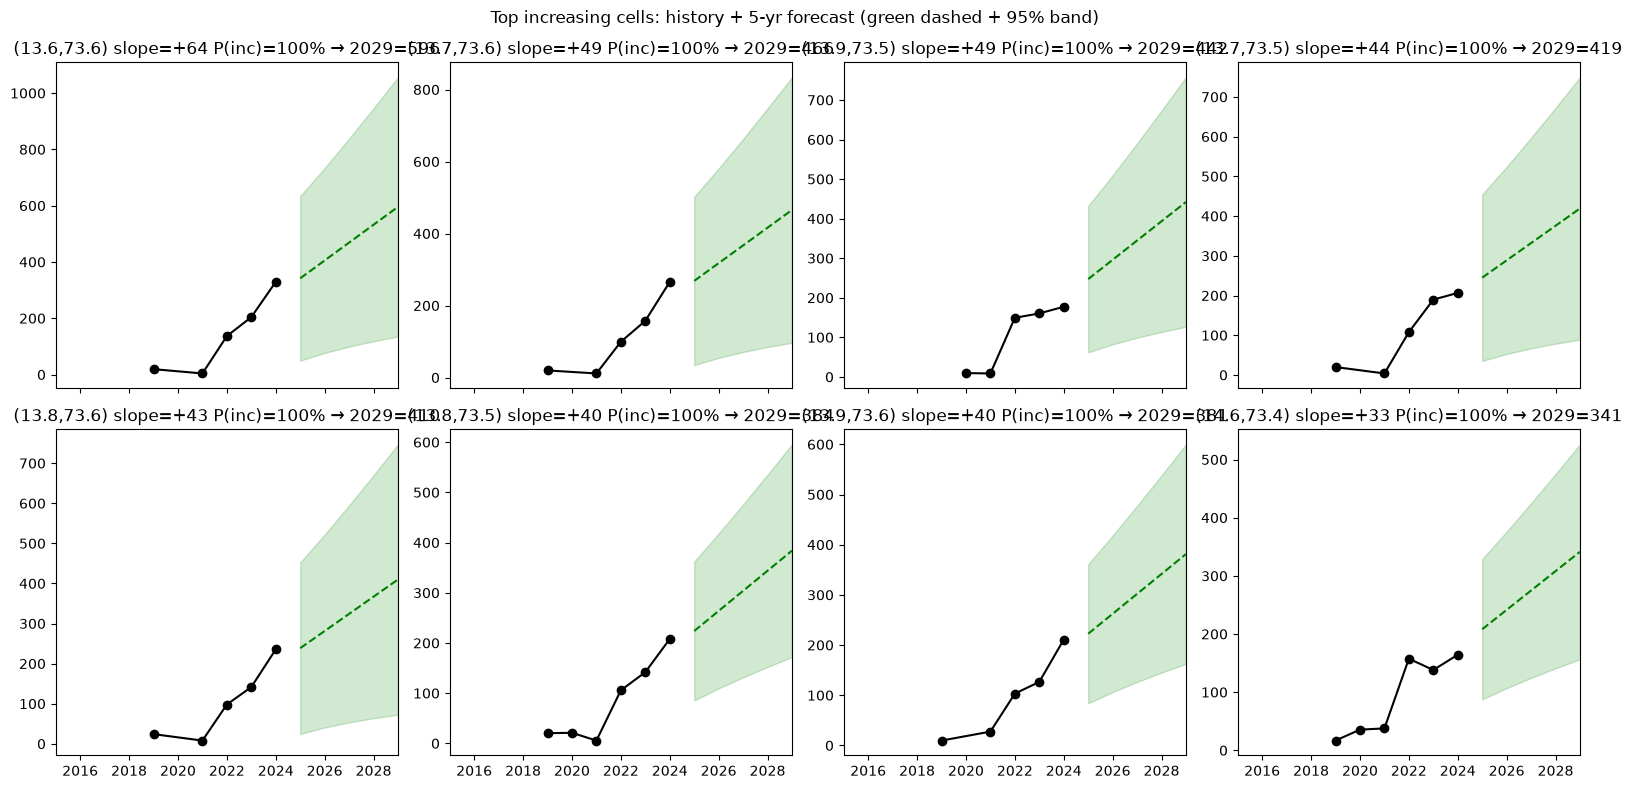

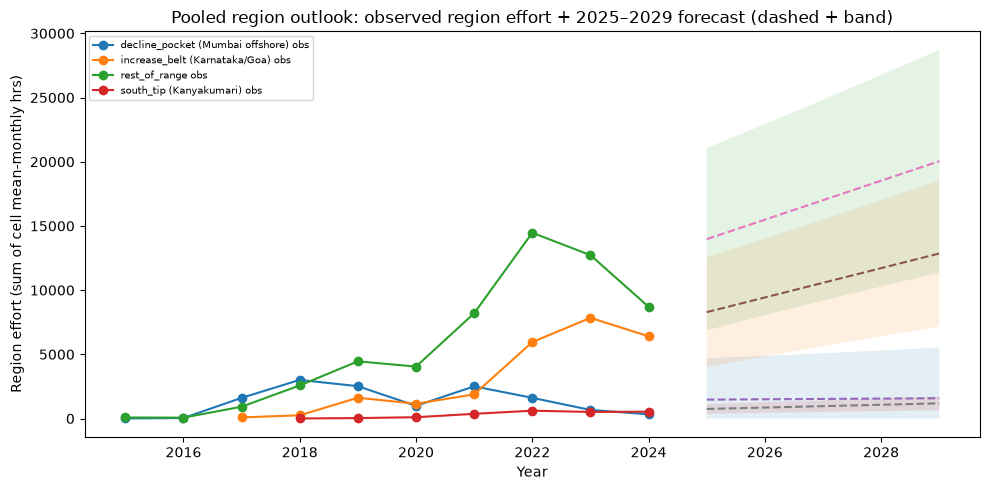

                             region  n_years    slope  p_value  p_decline  p_increase          future_class  last_effort  pred_2029  pi_lo_2029  pi_hi_2029  delta_2029  pct_2029
0  decline_pocket (Mumbai offshore)       10    26.25     0.84       0.42        0.58      Predicted Stable       330.12    1577.03        0.00     5524.33     1246.92    377.72
3           south_tip (Kanyakumari)        7   109.12     0.00       0.00        1.00  Predicted Increasing       533.06    1180.66      642.73     1718.59      647.60    121.49
1     increase_belt (Karnataka/Goa)        8  1142.00     0.00       0.00        1.00  Predicted Increasing      6405.81   12855.34     7154.76    18555.92     6449.53    100.68
2                     rest_of_range       10  1517.72     0.00       0.00        1.00  Predicted Increasing      8701.97   20041.98    11361.31    28722.65    11340.01    130.32


In [8]:
top_inc = CS[CS["future_class"] == "Predicted Increasing"].sort_values("pred_2029", ascending=False).head(8)
print(top_inc[["cell_ll_lat", "cell_ll_lon", "slope", "p_value", "last_effort", "pred_2029", "p_increase"]].round(2).to_string())
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True)
axes = axes.ravel()
for i, (_, r) in enumerate(top_inc.iterrows()):
    ax = axes[i]
    la, lo = r["cell_ll_lat"], r["cell_ll_lon"]
    hist = A[(A["cell_ll_lat"] == la) & (A["cell_ll_lon"] == lo)].sort_values("year")
    fc = CELL_LONG[(CELL_LONG["cell_ll_lat"] == la) & (CELL_LONG["cell_ll_lon"] == lo)].sort_values("year")
    ax.plot(hist["year"], hist["mean_monthly_fishing_hours"], "ko-")
    ax.plot(fc["year"], fc["yhat"], "g--")
    ax.fill_between(fc["year"], fc["pi_lo"], fc["pi_hi"], color="g", alpha=0.18)
    ax.set_title(f"({la},{lo}) slope=+{r['slope']:.0f} P(inc)={r['p_increase']:.0%} \u2192 2029={r['pred_2029']:.0f}")
    ax.set_xlim(2015, 2029)
fig.suptitle("Top increasing cells: history + 5-yr forecast (green dashed + 95% band)")
fig.tight_layout(); fig.savefig(FIG_DIR / "nb05_trajectories_increase_belt.png", dpi=200); plt.show()

fig2, ax2 = plt.subplots(figsize=(10, 5))
for reg, g in REG_ANN.groupby("region"):
    ax2.plot(g["year"], g["region_effort"], "o-", label=f"{reg} obs")
for reg, g in REG_LONG.groupby("region"):
    g = g.sort_values("year")
    ax2.plot(g["year"], g["yhat"], "--")
    ax2.fill_between(g["year"], g["pi_lo"], g["pi_hi"], alpha=0.12)
ax2.legend(fontsize=7); ax2.set_title("Pooled region outlook: observed region effort + 2025–2029 forecast (dashed + band)")
ax2.set_xlabel("Year"); ax2.set_ylabel("Region effort (sum of cell mean-monthly hrs)")
fig2.tight_layout(); fig2.savefig(FIG_DIR / "nb05_region_forecast.png", dpi=200); plt.show()
print(REG_SUM.round(2).to_string())

### 9. Watch-list (what to report)

**Decline:** Mumbai offshore pocket keeps falling — point forecasts hit ~0 by 2027–2029 but bands are wide (few points, short series). **Incline:** Karnataka/Goa belt (13.5–15.5N) keeps rising; south tip stable-up. Treat 2025–2026 direction as actionable, 2028–2029 values as scenarios. Cross-check any management call with `hours_per_active_vessel` (effort per vessel, not just AIS volume).

In [9]:
print("=== REGION 5-YR OUTLOOK ===")
print(REG_SUM.round(3).to_string())
print("\n=== ALL 7 PREDICTED DECLINERS (sorted by slope) ===")
print(CS[CS["future_class"] == "Predicted Declining"].sort_values("slope")[["cell_ll_lat", "cell_ll_lon", "n_years", "slope", "p_value", "p_decline", "last_effort", "pred_2025", "pred_2029", "pi_lo_2029", "pi_hi_2029"]].round(3).to_string())
print("\n=== TOP 10 PREDICTED INCREASERS (by 2029 forecast) ===")
print(CS[CS["future_class"] == "Predicted Increasing"].sort_values("pred_2029", ascending=False).head(10)[["cell_ll_lat", "cell_ll_lon", "n_years", "slope", "p_value", "p_increase", "last_effort", "pred_2025", "pred_2029", "pi_lo_2029", "pi_hi_2029"]].round(3).to_string())
print("\n=== CLASS COUNTS (future) ===")
print(CS["future_class"].value_counts().to_string())
print(CS.groupby(["region", "future_class"]).size().to_string())


=== REGION 5-YR OUTLOOK ===
                             region  n_years     slope  p_value  p_decline  p_increase          future_class  last_effort  pred_2029  pi_lo_2029  pi_hi_2029  delta_2029  pct_2029
0  decline_pocket (Mumbai offshore)       10    26.252    0.842      0.418       0.582      Predicted Stable      330.116   1577.031       0.000    5524.328    1246.915   377.721
3           south_tip (Kanyakumari)        7   109.117    0.004      0.000       1.000  Predicted Increasing      533.062   1180.659     642.733    1718.586     647.597   121.486
1     increase_belt (Karnataka/Goa)        8  1141.996    0.002      0.000       1.000  Predicted Increasing     6405.811  12855.340    7154.763   18555.918    6449.530   100.682
2                     rest_of_range       10  1517.720    0.001      0.000       1.000  Predicted Increasing     8701.970  20041.981   11361.312   28722.650   11340.011   130.315

=== ALL 7 PREDICTED DECLINERS (sorted by slope) ===
     cell_ll_lat  cell_l